# 03 — Bespoke Upsampling CNN

Compare ReLU and tanh across learning rates using the unchanged upsampled model.
The current controls specify three epochs, 10% linear warm-up, and zero weight
decay. Model definitions are separate from training and reporting helpers.

The card summarizes the architecture. Upsampling provides more spatial room for
the descent but adds no new image information; its benefit remains unproven.
Previous experiments are retained in evaluation records and saved artifacts,
not displayed as historical results in this runnable notebook.


In [1]:
from pathlib import Path
import sys
import importlib
from IPython.display import Image, display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from scripts.model import digit_experiment_helpers as experiments


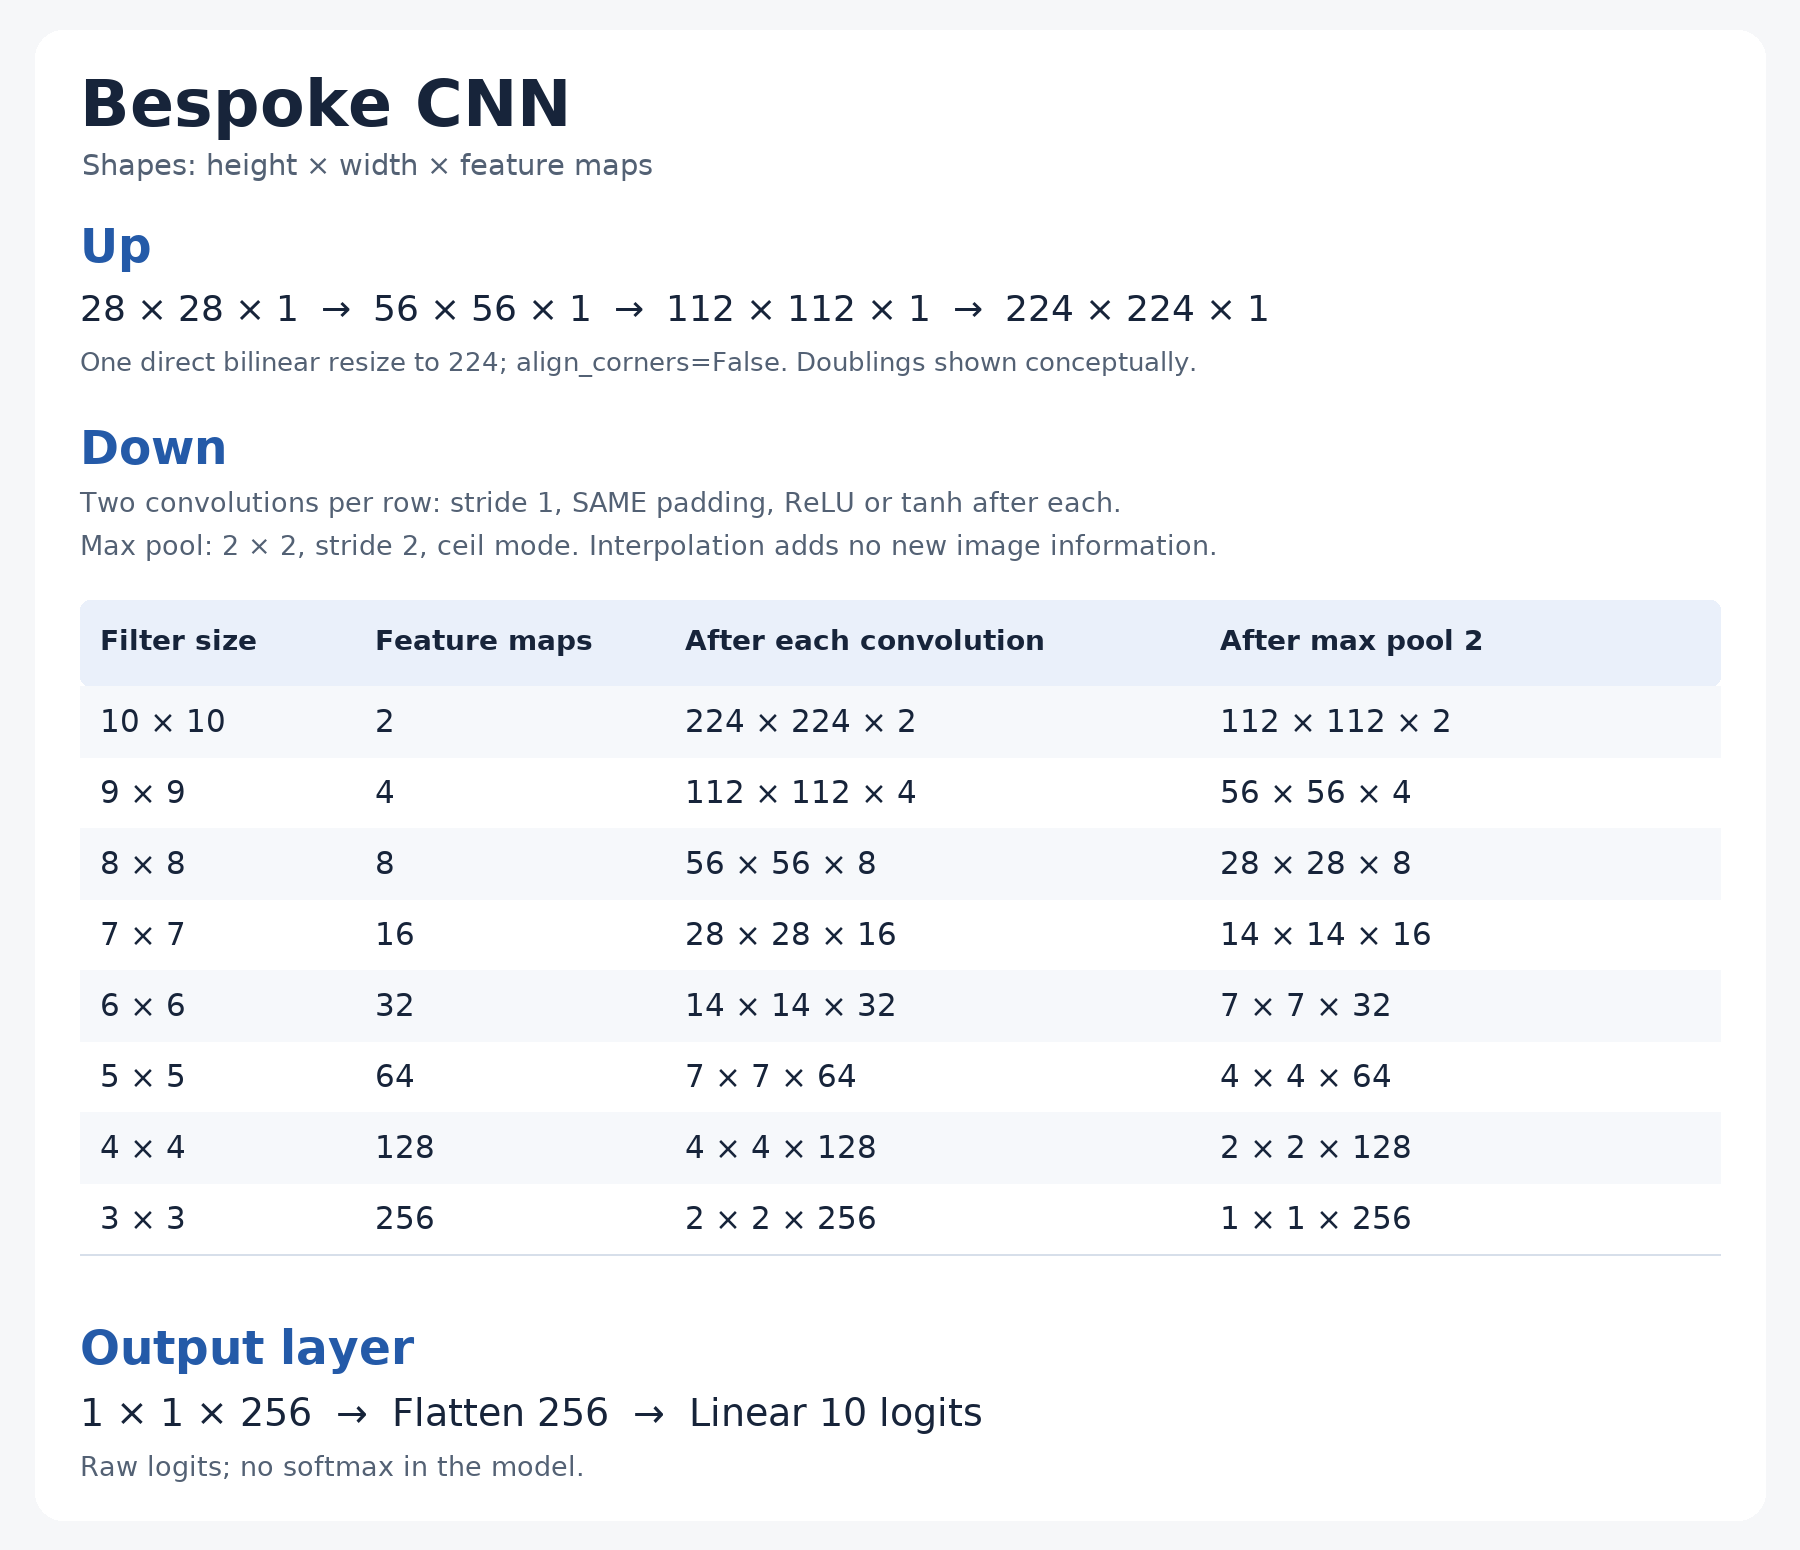

In [2]:
display(Image(filename=str(project_root / "docs/evaluations/assets/bespoke-224-architecture.png"), width=480))


## Matched experiment configuration

In [3]:
EPOCHS = 3
LEARNING_RATES = (1e-6, 1e-5, 1e-4, 1e-3)
WARMUP_FRACTION = 0.10
WEIGHT_DECAY = 0.0
ACTIVATIONS = ("relu", "tanh")
UPSAMPLE_MODE = "bilinear"
SEED = 42
BATCH_SIZE = 64
VALIDATION_FRACTION = 0.2

# Inspect/resume the stopped partial sweep, keeping its three completed runs.
# Set to None only to start a deliberate new sweep.
SWEEP_DIRECTORY = project_root / "data/experiments/bespoke_lr_sweep_20261030_031845_3f06eb0f"


## Inspect the data and unchanged architecture


In [4]:
experiments.show_dataset_summary()
experiments.inspect_bespoke_model(ACTIVATIONS[0], UPSAMPLE_MODE, SEED)


Training shape: (42000, 785)
Test shape: (28000, 784)
BespokeCNN: activation=relu, resize=bilinear, input=(1, 1, 28, 28)
Output shape: (1, 10)


/Users/KurtMeehanPro/Documents/code/venv/ml_py314/lib/python3.14/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(


## Run the serial sweep when ready

This cell starts training only when you deliberately execute it. No agent-owned
training is running now. An active managed-sweep lock prevents duplicate work.
The existing directory resumes only missing configurations; the interrupted
partial run restarts from initialization with a fresh ID because optimizer state
was not saved. Completed runs and earlier checkpoints remain untouched.

Each run has 1,575 updates. Linear warm-up uses target/158 for update 1, reaches
the target at update 158, then holds it; there is no learning-rate or weight decay.
Both activations run at each rate from low to high. Model definitions are separate
from training/report helpers. No concurrency or smaller-input architecture is used.


In [5]:
assert ACTIVATIONS == ("relu", "tanh") and UPSAMPLE_MODE == "bilinear"
assert SEED == 42 and BATCH_SIZE == 64 and VALIDATION_FRACTION == 0.2
SWEEP_DIRECTORY = experiments.run_bespoke_sweep(
    epochs=EPOCHS, learning_rates=LEARNING_RATES,
    warmup_fraction=WARMUP_FRACTION, weight_decay=WEIGHT_DECAY,
    sweep_directory=SWEEP_DIRECTORY,
)


SWEEP_DIRECTORY /Users/KurtMeehanPro/Documents/code/git/digit-recognizer/data/experiments/bespoke_lr_sweep_20261030_031845_3f06eb0f
KEEP completed relu target_lr=1e-06; no retraining
KEEP completed tanh target_lr=1e-06; no retraining
KEEP completed relu target_lr=1e-05; no retraining

START 20261030_042719_c95c0e13 | tanh | target_lr=1e-05 | 3 epochs | warmup=158/1575 steps
Training device: mps
/Users/KurtMeehanPro/Documents/code/venv/ml_py314/lib/python3.14/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(
Epoch 01/3 | train loss 2.1405, accuracy 17.86% | val loss 1.5517, accuracy 43.81%
Epoch 02/3 | train loss 1.1842, accuracy 58.74% | val loss 0.9807, accuracy 65.95%
Epoch 03/3 | train loss 0.8871, accuracy 69.65% | val loss 0.8102, accura

RuntimeError: Sweep stopped; inspect its preserved log/status before restarting.

## Results

This report selects only the sweep directory above. It reads saved configuration,
histories, logits, and labels without training or model inference. Completed runs
include summary/history/per-digit tables, confusion matrices, capped error
galleries, and comparisons. Incomplete runs are labeled separately. Nothing below
claims the stopped partial sweep completed all eight runs.


In [ ]:
experiments = importlib.reload(experiments)
experiments.refresh_helpers()
experiments.show_results(SWEEP_DIRECTORY)
